# Measuring portfolio sensitivity to estimation error

A small matrix error can be magnified by covariance inversion:

$$
\frac{\lVert(\Sigma+\Delta)^{-1}-\Sigma^{-1}\rVert_2}{\lVert\Sigma^{-1}\rVert_2}
\leq
\frac{\kappa_2(\Sigma)\varepsilon}{1-\kappa_2(\Sigma)\varepsilon},
\qquad
\varepsilon=\frac{\lVert\Delta\rVert_2}{\lVert\Sigma\rVert_2},
\qquad
\kappa_2(\Sigma)\varepsilon<1.
$$

Here, $\Sigma$ is a positive-definite covariance matrix, $\Delta$ is a covariance error, $\lVert\cdot\rVert_2$ is the spectral norm, $\varepsilon$ is the relative error size, and $\kappa_2(\Sigma)$ is the spectral condition number. The final condition is required for the finite bound shown.

Row,Quantity,Value
,String,Float64
1,Blocks,5.0
2,Assets per block,6.0
3,Assets,30.0
4,Within-block correlation,0.6
5,Observations,250.0
6,Observation to asset ratio,8.33333
7,Random seed,42.0


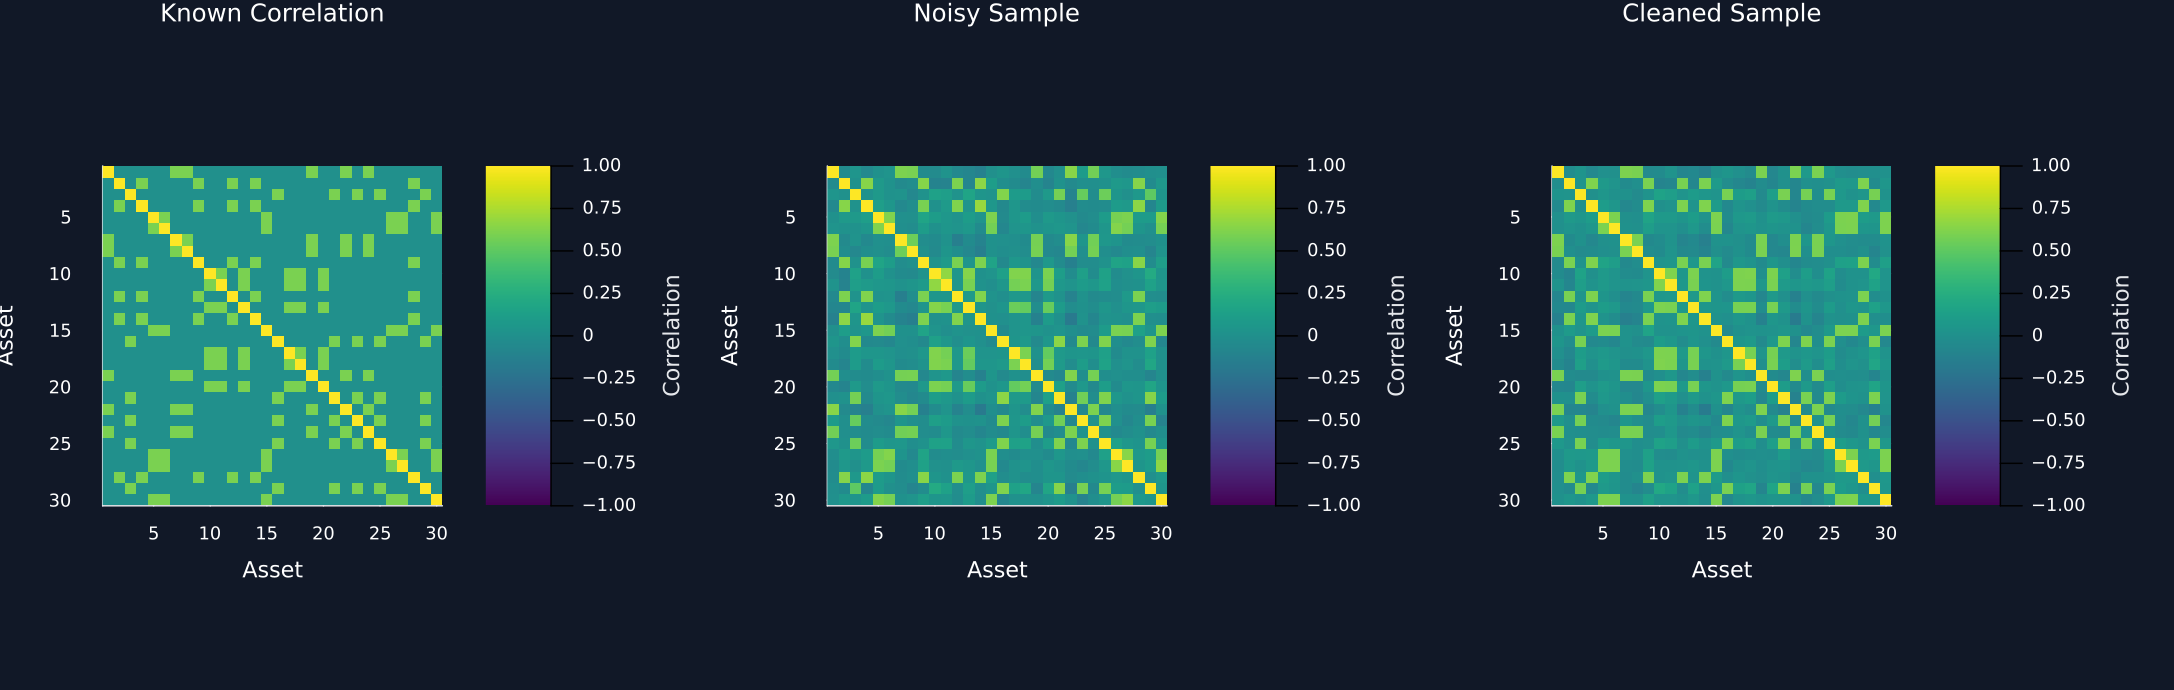

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("23_portfolio_geometry");
using CSV, Printf
using RiskLabAI.Data: corr_to_cov,cov_to_corr,denoise_cov,denoised_corr,denoised_corr2,find_max_eval,fit_kde,score_samples,marcenko_pastur_pdf,nercome_denoised_covariance,optimal_portfolio,optimal_portfolio_denoised,pca
data_path = dataset_path("french_49_industries")
archive_hash = BookSupport.TOML.parsefile(joinpath("..","data","inputs.toml"))["datasets"]["french_49_industries"]["original_sha256"]
data_hash = uppercase(archive_hash)
@assert isfile(data_path)
@assert data_hash == "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"

function matrix_frame(matrix;metadata...)
    prefix = DataFrame([name=>fill(value,size(matrix,1)) for (name,value) in pairs(metadata)]...)
    return hcat(prefix,DataFrame(row=collect(1:size(matrix,1))),DataFrame(matrix,["x"*string(index) for index in axes(matrix,2)]))
end

function covariance_fit(covariance,q,bandwidth)
    correlation = cov_to_corr(covariance)
    values,vectors = pca(correlation)
    cutoff,variance = find_max_eval(values,q,bandwidth)
    diagnostic = RiskLabAI.Data._mp_bounded_local_min(v->RiskLabAI.Data._mp_pdf_fit_error(v,q,values,bandwidth);derivative=v->RiskLabAI.Data._mp_pdf_fit_gradient(v,q,values,bandwidth))
    @assert variance==(diagnostic.converged ? diagnostic.variance : 1.)
    factors = count(>(cutoff),values)
    return (correlation=correlation,values=values,vectors=vectors,cutoff=cutoff,variance=variance,factors=factors,converged=diagnostic.converged,latent_variance=diagnostic.variance,objective=diagnostic.objective,iterations=diagnostic.iterations)
end

function add_fliers!(figure,groups)
    for (index,values) in enumerate(groups)
        lower,upper = quantile(values,[.25,.75])
        spread = upper-lower
        outside = values[(values.<lower-1.5spread).|(values.>upper+1.5spread)]
        scatter!(figure,fill(index,length(outside)),outside;color=palette.text,markersize=3,markerstrokewidth=0,label=false)
    end
    return figure
end
function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end
using SHA, TOML
using RiskLabAI.Optimization: get_optimal_portfolio_weights
using RiskLabAI.Data: form_true_matrix
include(joinpath("..","support","BookPortfolioGeometry.jl"))
using .BookPortfolioGeometry
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter20-"*replace(name,"_"=>"-"))
function portfolio_record(name,weights,expected_return,covariance)
    return (Portfolio=name,expected=dot(weights,expected_return),volatility=sqrt(dot(weights,covariance*weights)),largest=maximum(weights),smallest=minimum(weights),gross=sum(abs,weights),concentration=sum(abs2,weights),effective=1/sum(abs2,weights))
end
function portfolio_table(records)
    frame = DataFrame(records)
    rename!(frame,["Portfolio","Expected annual return","Annual volatility","Largest long weight","Smallest weight","Gross exposure","Weight concentration","Effective holdings"])
    return frame
end
function weight_frame(weights;metadata...)
    frame = DataFrame([key=>fill(value,length(weights)) for (key,value) in pairs(metadata)]...)
    return hcat(frame,DataFrame(asset=1:length(weights),weight=weights))
end
function save_noise_fit(covariance,q,name)
    fitted = covariance_fit(covariance,q,0.01)
    save_data(DataFrame(variance=[fitted.variance],cutoff=[fitted.cutoff],factors=[fitted.factors],converged=[fitted.converged],latent_variance=[fitted.latent_variance],objective=[fitted.objective],iterations=[fitted.iterations]),paths,name)
    return denoise_cov(covariance,q)
end
data_provenance = DataFrame("Field"=>["Archive","Provider","Return type","Analysis start","Analysis end","Complete dates","Industry portfolios","File checksum"],"Value"=>["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library","Daily value-weighted return",string(first(industry_dates)),string(last(industry_dates)),string(size(industry_returns,1)),string(size(industry_returns,2)),data_hash])
@assert size(industry_returns)==(1760,49)
@assert first(industry_dates)==Date(2019,1,2)
@assert last(industry_dates)==Date(2025,12,31)
save_data(hcat(DataFrame(date=industry_dates),DataFrame(industry_returns,industry_names)),paths,"sensitivity_observations");
random_root = joinpath("..","data","chapter23_random_inputs")
input_manifest = joinpath(random_root,"inputs.toml")
@assert bytes2hex(sha256(read(input_manifest)))=="be6c6a3f9e373ada58cbe489fbf835461327ea5bd0e4c1220671e40d7dc8105d"
input_specification = TOML.parsefile(input_manifest)["files"]
function random_input(name)
    path = joinpath(random_root,name)
    @assert bytes2hex(sha256(read(path)))==input_specification[name]["sha256"]
    frame = CSV.read(path,DataFrame)
    @assert size(frame)==(input_specification[name]["rows"],input_specification[name]["columns"])
    return frame
end
coordinate_path = joinpath(random_root,"coordinate_convention.toml")
@assert bytes2hex(sha256(read(coordinate_path)))=="db8a538f9a65b95eab8acd74758cc3763e944e9dae1d3b78fd26012e20e26592"
orientation = TOML.parsefile(coordinate_path)["orientation"]
draws = random_input("true_matrix_draws.csv")
block_count,block_size,within_block_correlation,observation_count = 5,6,0.60,250
true_mean,true_covariance = form_true_matrix(block_count,block_size,within_block_correlation;permutation=draws.permutation,standard_deviation_draws=draws.standard_deviation,normal_draws=draws.normal)
synthetic_sample = public_normal_samples(true_mean,true_covariance,Matrix{Float64}(random_input("sample_normals.csv"));orientation)
sample_mean,sample_covariance = vec(mean(synthetic_sample;dims=1)),cov(synthetic_sample)
asset_count = size(true_covariance,1)
observation_asset_ratio = observation_count/asset_count
cleaned_covariance = save_noise_fit(sample_covariance,observation_asset_ratio,"one_path_noise_fit")
true_correlation,sample_correlation,cleaned_correlation = cov_to_corr.([true_covariance,sample_covariance,cleaned_covariance])
known_truth_design = DataFrame("Quantity"=>["Blocks","Assets per block","Assets","Within-block correlation","Observations","Observation to asset ratio","Random seed"],"Value"=>[block_count,block_size,asset_count,within_block_correlation,observation_count,observation_asset_ratio,42])
table(known_truth_design,"known_truth_design","Visible design of the controlled block-covariance experiment.")
save_data(matrix_frame(synthetic_sample),paths,"synthetic_sample")
save_data(DataFrame(asset=1:30,true_mean=true_mean,sample_mean=sample_mean),paths,"synthetic_means")
save_data(reduce(vcat,[matrix_frame(matrix;method=name) for (name,matrix) in [("Known",true_covariance),("Sample",sample_covariance),("Cleaned",cleaned_covariance)]]),paths,"synthetic_covariances")
panels = [heatmap(1:asset_count,1:asset_count,matrix;color=:viridis,clims=(-1,1),yflip=true,aspect_ratio=:equal,xlims=(0.5,30.5),ylims=(0.5,30.5),widen=false,title,xlabel="Asset",ylabel="Asset",colorbar_title="Correlation") for (matrix,title) in [(true_correlation,"Known Correlation"),(sample_correlation,"Noisy Sample"),(cleaned_correlation,"Cleaned Sample")]]
save_figure(plot(panels...;layout=(1,3),size=(1450,460)),paths,"true_sample_cleaned_correlations")


## Comparing raw covariance with a cleaned estimate

Weight error and variance under the known covariance are measured by:

$$
\operatorname{RMSE}_w(m)
=\sqrt{\frac{1}{N}\sum_{i=1}^{N}(\widehat w_{i,m}-w_{i,0})^2},
\qquad
V_m=\widehat w_m^{\mathsf T}\Sigma_0\widehat w_m,
\qquad
\rho_m=\frac{V_m}{V_0}.
$$

Here, $N$ is the number of assets, $m$ names a covariance estimate, $\widehat w_{i,m}$ is its estimated weight for asset $i$, $w_{i,0}$ is the known optimal weight, $\Sigma_0$ is the covariance used to generate returns, $V_m$ is variance under that known covariance, $V_0$ is the smallest known variance, and $\rho_m$ is the true-variance ratio.

Row,Matrix,Relative covariance error,Correlation condition number,Smallest correlation eigenvalue
,String,Float64,Float64,Float64
1,Known covariance,0.0,10.0,0.4
2,Sample covariance,0.19727,28.6092,0.170466
3,Cleaned covariance,0.180731,13.1605,0.371333


Row,Method,Weight root mean squared error,Weight absolute error,True variance,True variance ratio,Gross exposure,Largest absolute weight
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Known GMV,0.0,0.0,0.00057164,1.0,1.59431,0.208659
2,Raw inverse variance,0.0449103,1.1089,0.00105953,1.8535,1.0,0.0930312
3,Cleaned inverse variance,0.0449103,1.1089,0.00105953,1.8535,1.0,0.0930312
4,Raw GMV,0.0170797,0.403453,0.000611319,1.06941,1.63923,0.24349
5,Cleaned GMV,0.0116338,0.250562,0.000589522,1.03128,1.63372,0.232766


Row,Preliminary experiment,Chapter 20 result,Chapter routing
,String,String,String
1,Known shuffled block covariance,Reproduced,Chapter 20
2,Noisy sample covariance,Reproduced,Chapter 20
3,Marcenko-Pastur cleaning,Reproduced,Chapter 20
4,Inverse-variance portfolios,Reproduced,Chapter 20
5,Raw and cleaned GMV,Reproduced,Chapter 20
6,Known true-variance comparison,Reproduced,Chapter 20


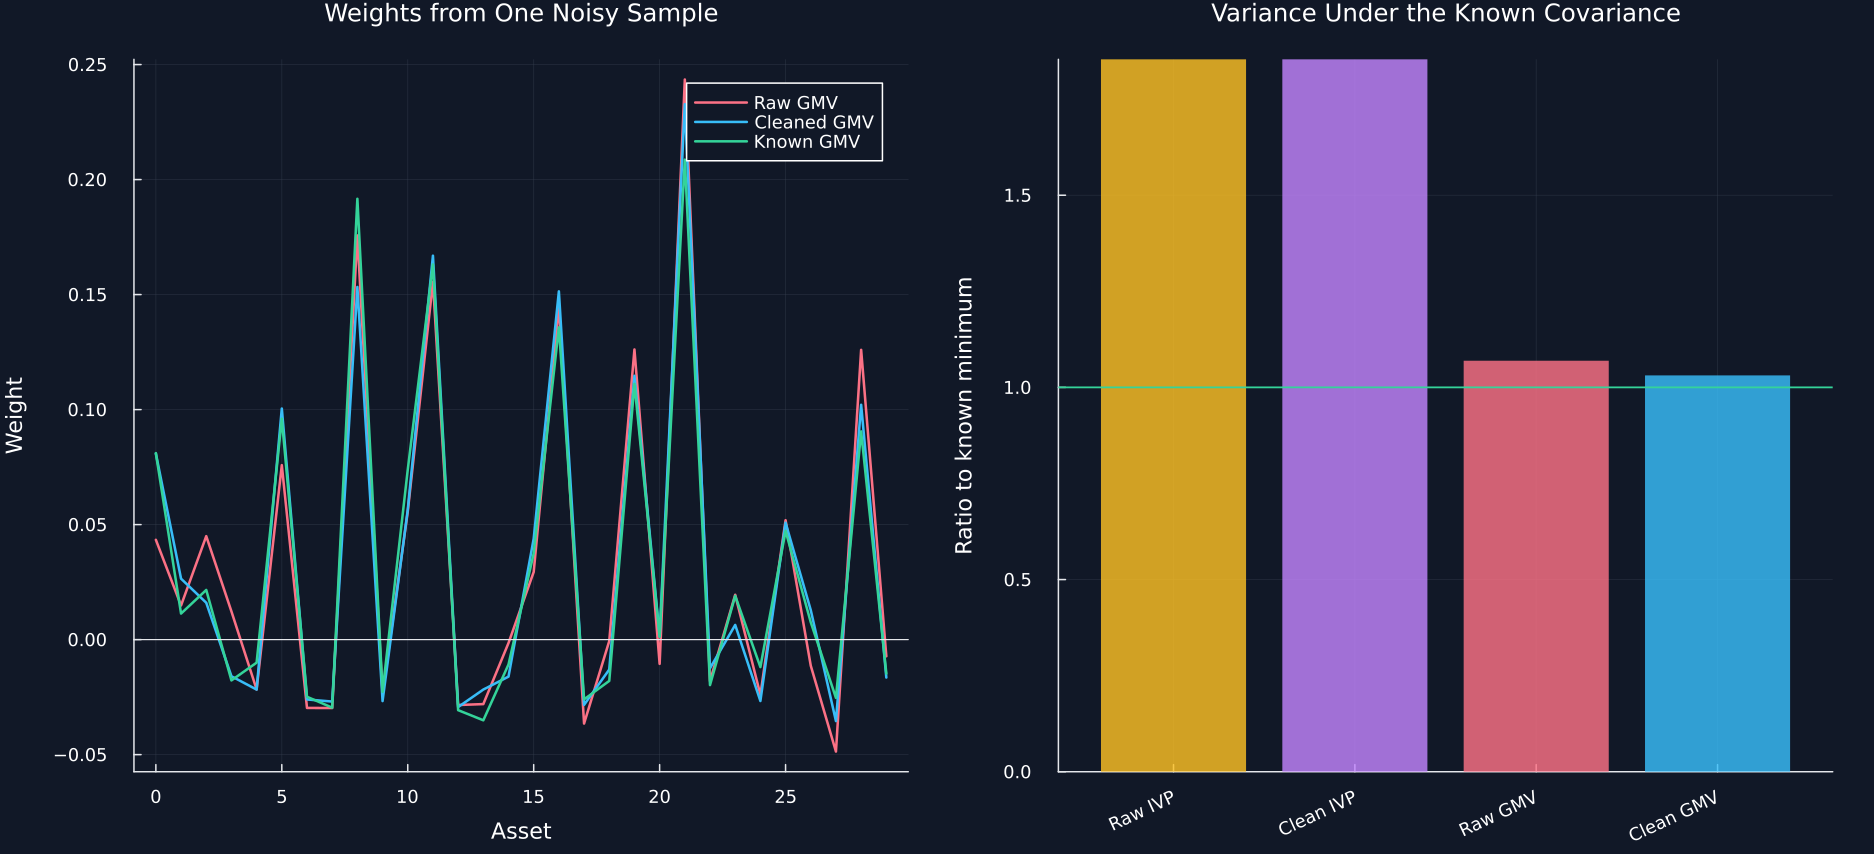

In [2]:
true_gmv = global_minimum_variance(true_covariance)
raw_gmv = get_optimal_portfolio_weights(sample_covariance)
clean_gmv = get_optimal_portfolio_weights(cleaned_covariance)
raw_ivp,clean_ivp = inverse_variance(sample_covariance),inverse_variance(cleaned_covariance)
true_variance_floor = dot(true_gmv,true_covariance*true_gmv)
one_path_weights = ["Known GMV"=>true_gmv,"Raw inverse variance"=>raw_ivp,"Cleaned inverse variance"=>clean_ivp,"Raw GMV"=>raw_gmv,"Cleaned GMV"=>clean_gmv]
one_path_portfolio_summary = DataFrame([(Method=name,rmse=sqrt(mean((weights-true_gmv).^2)),absolute=sum(abs,weights-true_gmv),variance=dot(weights,true_covariance*weights),ratio=dot(weights,true_covariance*weights)/true_variance_floor,gross=sum(abs,weights),largest=maximum(abs,weights)) for (name,weights) in one_path_weights])
rename!(one_path_portfolio_summary,["Method","Weight root mean squared error","Weight absolute error","True variance","True variance ratio","Gross exposure","Largest absolute weight"])
covariance_summary = DataFrame("Matrix"=>["Known covariance","Sample covariance","Cleaned covariance"],"Relative covariance error"=>[0.0,norm(sample_covariance-true_covariance)/norm(true_covariance),norm(cleaned_covariance-true_covariance)/norm(true_covariance)],"Correlation condition number"=>cond.([true_correlation,sample_correlation,cleaned_correlation]),"Smallest correlation eigenvalue"=>[eigmin(Symmetric(matrix)) for matrix in [true_correlation,sample_correlation,cleaned_correlation]])
preliminary_reproduction = DataFrame("Preliminary experiment"=>["Known shuffled block covariance","Noisy sample covariance","Marcenko-Pastur cleaning","Inverse-variance portfolios","Raw and cleaned GMV","Known true-variance comparison"],"Chapter 20 result"=>fill("Reproduced",6),"Chapter routing"=>fill("Chapter 20",6))
table(covariance_summary,"known_truth_covariance_summary","Known, noisy, and cleaned covariance diagnostics for one controlled sample.")
table(one_path_portfolio_summary,"one_path_portfolio_summary","Portfolio errors and true risk for one controlled sample.")
table(preliminary_reproduction,"preliminary_portfolio_reproduction","Chapter 20 coverage of the preliminary portfolio-construction experiment.")
save_data(reduce(vcat,[weight_frame(weights;method=name) for (name,weights) in one_path_weights]),paths,"one_path_weights")
p1 = plot(;title="Weights from One Noisy Sample",xlabel="Asset",ylabel="Weight",legend=:topright)
for (name,weights,color) in [("Raw GMV",raw_gmv,palette.rose),("Cleaned GMV",clean_gmv,palette.cyan),("Known GMV",true_gmv,palette.green)]
    plot!(p1,0:asset_count-1,weights;color,label=name,linewidth=1.7)
end
hline!(p1,[0.0];color=palette.text,linewidth=0.8,label=false)
p2 = bar(1:4,one_path_portfolio_summary[2:end,"True variance ratio"];color=[palette.amber,violet,palette.rose,palette.cyan],alpha=0.82,linealpha=0,xticks=(1:4,["Raw IVP","Clean IVP","Raw GMV","Clean GMV"]),xrotation=25,title="Variance Under the Known Covariance",ylabel="Ratio to known minimum",legend=false)
hline!(p2,[1.0];color=palette.green,linewidth=1.2,label=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,570)),paths,"one_path_weights_true_risk")


## Isolating covariance error from expected-return error

The first-order change in a normalized inverse-covariance portfolio separates covariance and expected-return errors:

$$
d(\Sigma^{-1}\mu)
=-\Sigma^{-1}(d\Sigma)\Sigma^{-1}\mu+\Sigma^{-1}d\mu,
\qquad
dw=d\left(\frac{\Sigma^{-1}\mu}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mu}\right).
$$

Here, $d\Sigma$ is a small covariance change, $d\mu$ is a small expected-return change, $\Sigma^{-1}\mu$ is the unnormalized portfolio direction, and $dw$ is the resulting first-order change after the weights are rescaled to sum to one.

Row,Stress,Relative input change,Weight absolute change,True variance ratio
,String,Float64,Float64,Float64
1,Covariance blend at 10 percent,0.0690865,0.13212,1.01188
2,Covariance blend at 25 percent,0.172716,0.320654,1.06995
3,Covariance blend at 50 percent,0.345432,0.61154,1.25442
4,Mean change at 10 percent,0.1,8.23879,1.39614
5,Mean change at 25 percent,0.25,24.7518,2.61278
6,Mean change at 50 percent,0.5,74.5761,9.70141


Row,Perturbation level,Relative covariance change,Condition number,Weight absolute change,True variance ratio
,Float64,Float64,Float64,Float64,Float64
1,0.0,0.0,10.0,0.0,1.0
2,0.025,0.0172716,9.45783,0.0335346,1.00077
3,0.05,0.0345432,8.95349,0.0667294,1.00303
4,0.075,0.0518149,8.48315,0.0995897,1.00675
5,0.1,0.0690865,8.04348,0.13212,1.01188
6,0.125,0.0863581,7.63158,0.164327,1.01837
7,0.15,0.10363,7.2449,0.196213,1.02619
8,0.175,0.120901,6.88119,0.227784,1.0353
9,0.2,0.138173,6.53846,0.259045,1.04565


Row,Perturbation level,Relative mean change,Weight absolute change,True variance ratio,Expected-return change
,Float64,Float64,Float64,Float64,Float64
1,0.0,0.0,0.0,1.0,0.0
2,0.025,0.025,1.90021,1.07891,0.122425
3,0.05,0.05,3.90112,1.17008,0.251338
4,0.075,0.075,6.01093,1.27517,0.387267
5,0.1,0.1,8.23879,1.39614,0.530802
6,0.125,0.125,10.5949,1.53524,0.6826
7,0.15,0.15,13.0907,1.69511,0.843394
8,0.175,0.175,15.7388,1.87883,1.01401
9,0.2,0.2,18.5539,2.09002,1.19537


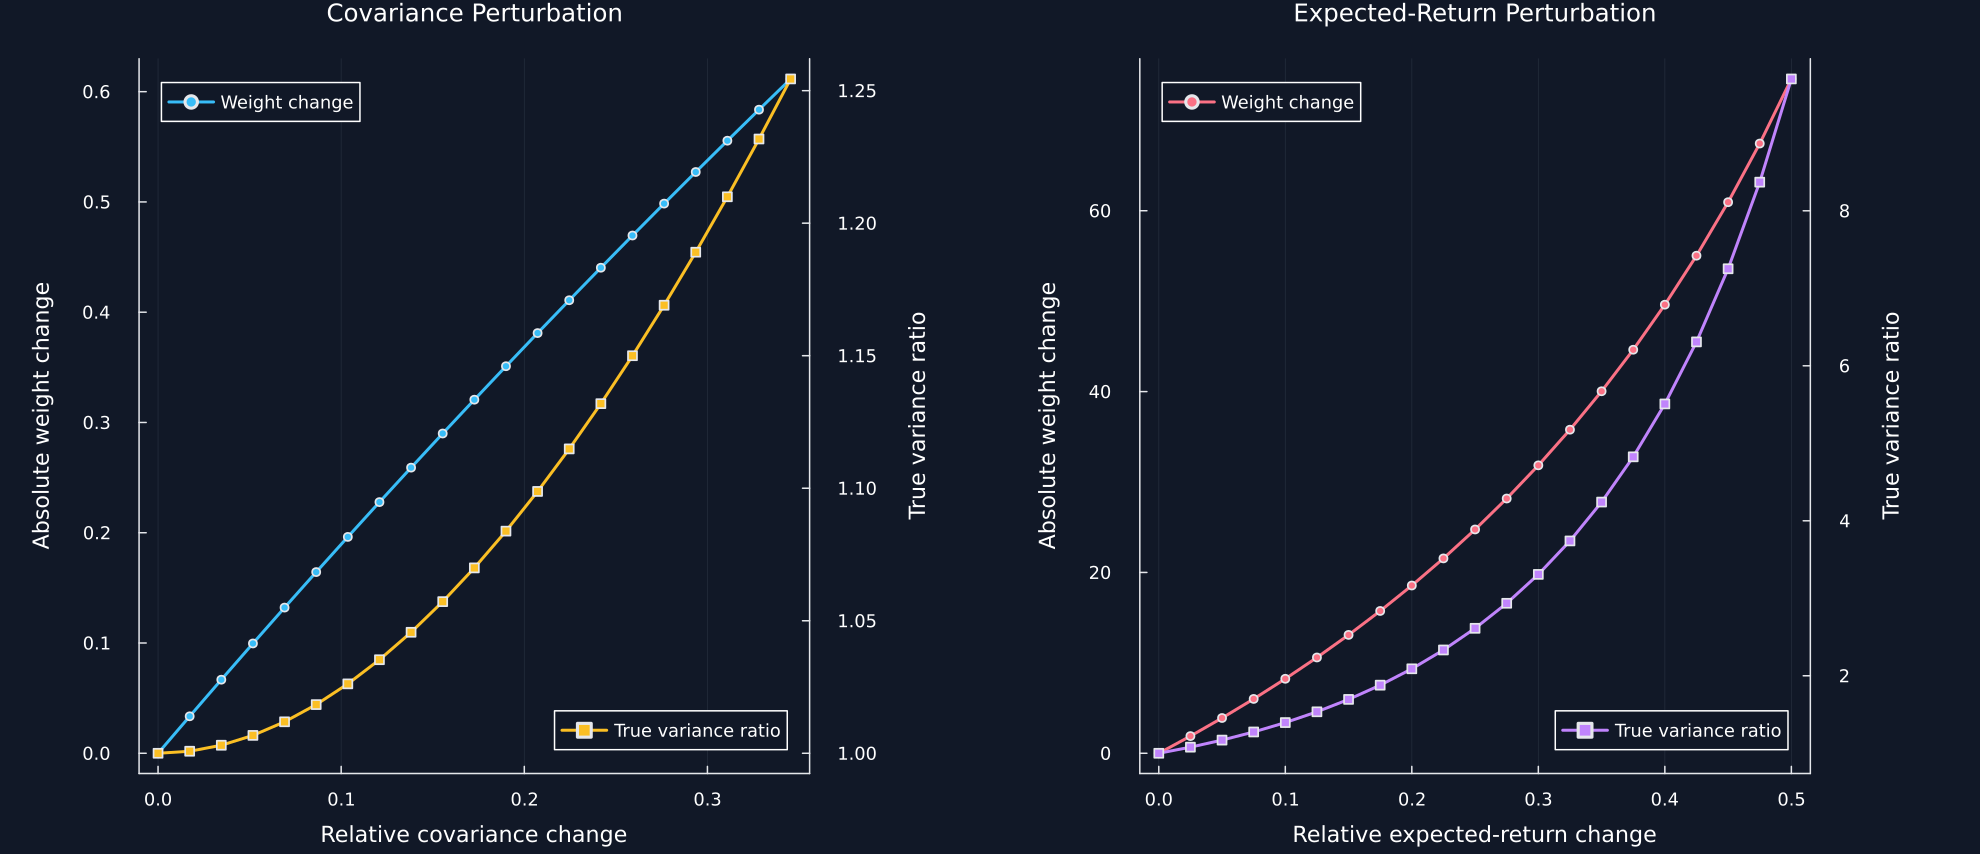

In [3]:
covariance_levels = collect(range(0.0,0.50;length=21))
diagonal_covariance = Diagonal(diag(true_covariance))
covariance_sensitivity_rows,mean_sensitivity_rows = NamedTuple[],NamedTuple[]
base_mean_weights = mean_return_weighted(true_covariance,true_mean)
mean_direction = collect(range(-1.0,1.0;length=asset_count))
mean_direction .-= mean(mean_direction)
mean_direction ./= norm(mean_direction)
for level in covariance_levels
    perturbed_covariance = (1-level)*true_covariance+level*diagonal_covariance
    weights = global_minimum_variance(perturbed_covariance)
    push!(covariance_sensitivity_rows,(level=level,relative=opnorm(perturbed_covariance-true_covariance)/opnorm(true_covariance),condition=cond(cov_to_corr(perturbed_covariance)),change=sum(abs,weights-true_gmv),ratio=dot(weights,true_covariance*weights)/true_variance_floor))
    perturbed_mean = true_mean+level*norm(true_mean)*mean_direction
    weights = mean_return_weighted(true_covariance,perturbed_mean)
    push!(mean_sensitivity_rows,(level=level,relative=norm(perturbed_mean-true_mean)/norm(true_mean),change=sum(abs,weights-base_mean_weights),ratio=dot(weights,true_covariance*weights)/dot(base_mean_weights,true_covariance*base_mean_weights),expected_change=dot(weights,true_mean)-dot(base_mean_weights,true_mean)))
end
covariance_sensitivity,mean_sensitivity = DataFrame(covariance_sensitivity_rows),DataFrame(mean_sensitivity_rows)
rename!(covariance_sensitivity,["Perturbation level","Relative covariance change","Condition number","Weight absolute change","True variance ratio"])
rename!(mean_sensitivity,["Perturbation level","Relative mean change","Weight absolute change","True variance ratio","Expected-return change"])
selected = [5,11,21]
sensitivity_summary = DataFrame("Stress"=>["Covariance blend at 10 percent","Covariance blend at 25 percent","Covariance blend at 50 percent","Mean change at 10 percent","Mean change at 25 percent","Mean change at 50 percent"],"Relative input change"=>vcat(covariance_sensitivity[selected,"Relative covariance change"],[0.10,0.25,0.50]),"Weight absolute change"=>vcat(covariance_sensitivity[selected,"Weight absolute change"],mean_sensitivity[selected,"Weight absolute change"]),"True variance ratio"=>vcat(covariance_sensitivity[selected,"True variance ratio"],mean_sensitivity[selected,"True variance ratio"]))
table(sensitivity_summary,"input_sensitivity_summary","Weight and true-risk changes under controlled covariance and mean perturbations.")
table(covariance_sensitivity,"covariance_sensitivity_audit","Complete controlled covariance-sensitivity path.")
table(mean_sensitivity,"mean_sensitivity_audit","Complete controlled expected-return-sensitivity path.")
p1 = plot(covariance_sensitivity[!,"Relative covariance change"],covariance_sensitivity[!,"Weight absolute change"];color=palette.cyan,marker=:circle,markersize=3,label="Weight change",legend=:topleft,title="Covariance Perturbation",xlabel="Relative covariance change",ylabel="Absolute weight change")
plot!(twinx(p1),covariance_sensitivity[!,"Relative covariance change"],covariance_sensitivity[!,"True variance ratio"];color=palette.amber,marker=:square,markersize=3,label="True variance ratio",legend=:bottomright,ylabel="True variance ratio",grid=false)
p2 = plot(mean_sensitivity[!,"Relative mean change"],mean_sensitivity[!,"Weight absolute change"];color=palette.rose,marker=:circle,markersize=3,label="Weight change",legend=:topleft,title="Expected-Return Perturbation",xlabel="Relative expected-return change",ylabel="Absolute weight change")
plot!(twinx(p2),mean_sensitivity[!,"Relative mean change"],mean_sensitivity[!,"True variance ratio"];color=violet,marker=:square,markersize=3,label="True variance ratio",legend=:bottomright,ylabel="True variance ratio",grid=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1320,570),right_margin=18Plots.mm,left_margin=10Plots.mm),paths,"covariance_mean_sensitivity")


## Repeated Known-Truth Samples

Repeated samples estimate the average true-risk ratio and its simulation uncertainty:

$$
\overline\rho_m=\frac{1}{M}\sum_{b=1}^{M}\rho_{b,m},
\qquad
\widehat{\operatorname{SE}}(\overline\rho_m)
=\frac{s_m}{\sqrt{M}}.
$$

Here, $M$ is the number of repeated samples, $b$ labels a sample, $m$ labels a portfolio method, $\rho_{b,m}$ is its true-variance ratio in sample $b$, $s_m$ is the sample standard deviation of those ratios, and $\widehat{\operatorname{SE}}$ is the estimated simulation standard error.

Row,Method,Mean weight root mean squared error,Mean true variance ratio,Median true variance ratio,True variance ratio standard error,Mean gross exposure
,String,Float64,Float64,Float64,Float64,Float64
1,Raw inverse variance,0.0449491,1.8618,1.86087,0.00255343,1.0
2,Cleaned inverse variance,0.0449491,1.8618,1.86087,0.00255343,1.0
3,Raw GMV,0.023841,1.12487,1.12254,0.00538141,1.67002
4,Cleaned GMV,0.0150582,1.05723,1.05416,0.00249022,1.56948


Row,Quantity,Value
,String,Float64
1,Repetitions,40.0
2,Cleaned GMV lower true variance,40.0
3,Raw GMV mean true variance ratio,1.12487
4,Cleaned GMV mean true variance ratio,1.05723
5,Mean paired ratio difference,-0.0676412


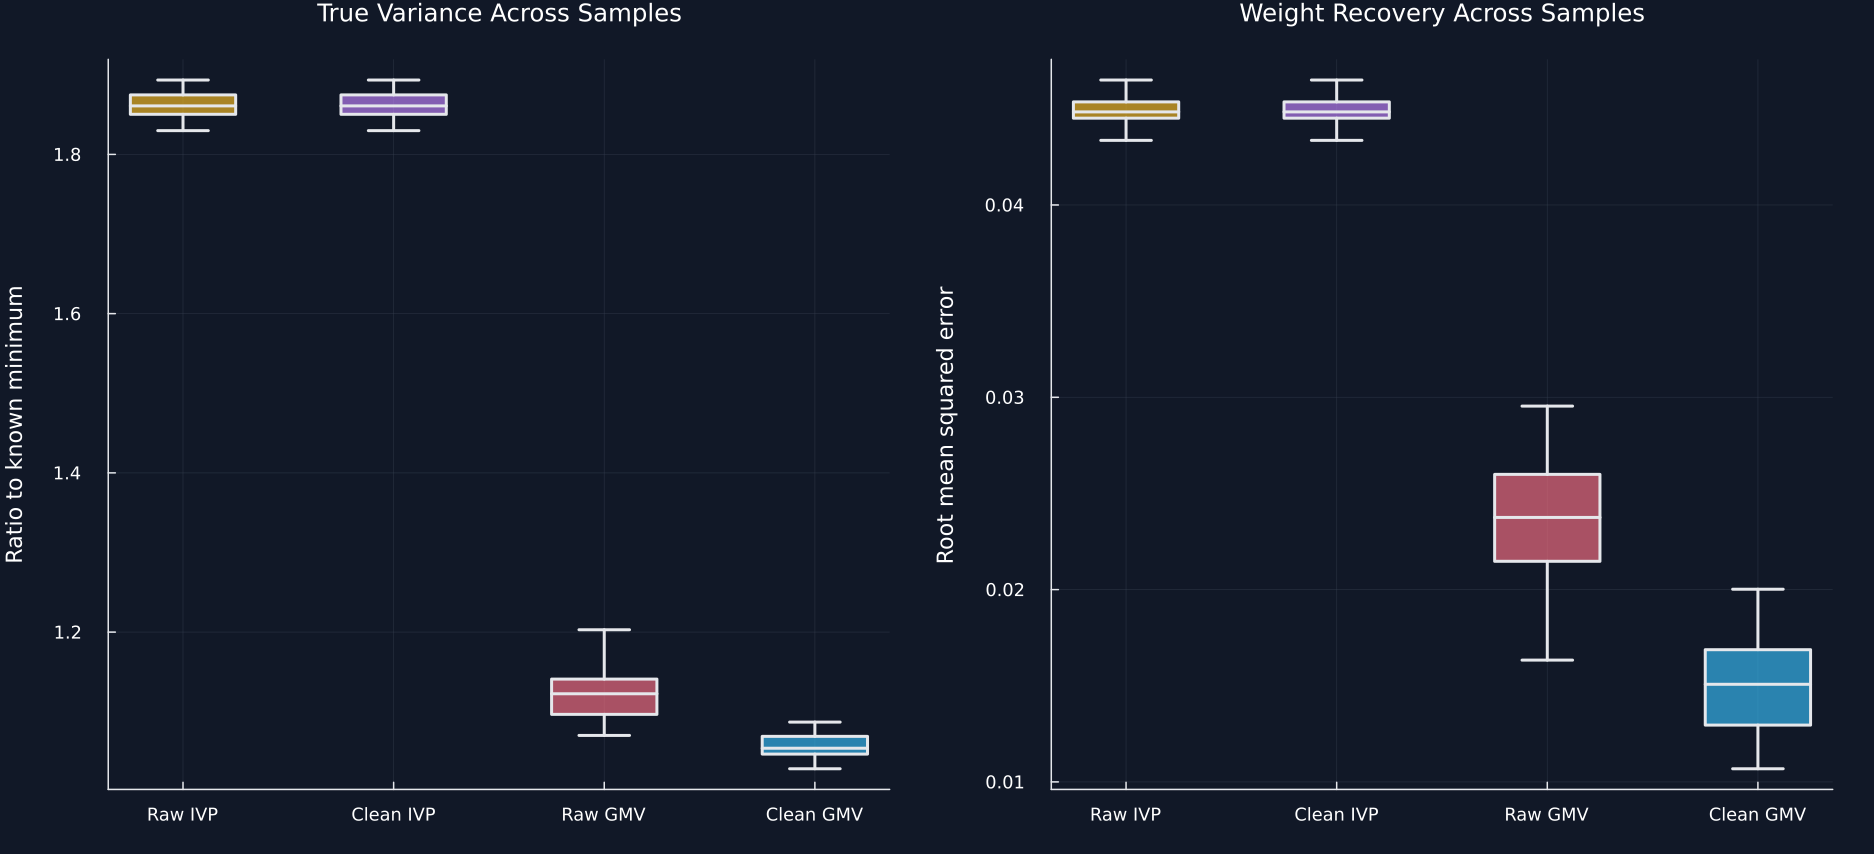

In [4]:
repetition_count = 40
method_order = ["Raw inverse variance","Cleaned inverse variance","Raw GMV","Cleaned GMV"]
repeated_rows,weight_rows = NamedTuple[],DataFrame[]
for repetition in 1:repetition_count
    innovations = Matrix{Float64}(random_input("repeated_normals_"*string(repetition)*".csv"))
    samples = public_normal_samples(true_mean,true_covariance,innovations;orientation)
    covariance = cov(samples)
    cleaned = save_noise_fit(covariance,observation_asset_ratio,"repeated_noise_fit_"*string(repetition))
    method_weights = [inverse_variance(covariance),inverse_variance(cleaned),global_minimum_variance(covariance),global_minimum_variance(cleaned)]
    for (method,weights) in zip(method_order,method_weights)
        push!(repeated_rows,(Repetition=repetition,Method=method,rmse=sqrt(mean((weights-true_gmv).^2)),ratio=dot(weights,true_covariance*weights)/true_variance_floor,gross=sum(abs,weights)))
        push!(weight_rows,weight_frame(weights;repetition,method))
    end
    save_data(matrix_frame(covariance),paths,"repeated_covariance_"*string(repetition))
    save_data(matrix_frame(cleaned),paths,"repeated_cleaned_"*string(repetition))
    save_data(DataFrame(asset=1:asset_count,mean=vec(mean(samples;dims=1))),paths,"repeated_mean_"*string(repetition))
end
repeated_results = DataFrame(repeated_rows)
rename!(repeated_results,["Repetition","Method","Weight root mean squared error","True variance ratio","Gross exposure"])
repeated_summary = DataFrame([(Method=method,rmse=mean(group[!,"Weight root mean squared error"]),ratio=mean(group[!,"True variance ratio"]),median_ratio=median(group[!,"True variance ratio"]),standard_error=std(group[!,"True variance ratio"])/sqrt(repetition_count),gross=mean(group[!,"Gross exposure"])) for method in method_order for group in [repeated_results[repeated_results.Method.==method,:]]])
rename!(repeated_summary,["Method","Mean weight root mean squared error","Mean true variance ratio","Median true variance ratio","True variance ratio standard error","Mean gross exposure"])
raw_gmv_ratios = repeated_results[repeated_results.Method.=="Raw GMV","True variance ratio"]
cleaned_gmv_ratios = repeated_results[repeated_results.Method.=="Cleaned GMV","True variance ratio"]
paired_summary = DataFrame("Quantity"=>["Repetitions","Cleaned GMV lower true variance","Raw GMV mean true variance ratio","Cleaned GMV mean true variance ratio","Mean paired ratio difference"],"Value"=>[repetition_count,count(cleaned_gmv_ratios.<raw_gmv_ratios),mean(raw_gmv_ratios),mean(cleaned_gmv_ratios),mean(cleaned_gmv_ratios-raw_gmv_ratios)])
table(repeated_summary,"repeated_known_truth_summary","Portfolio errors across forty controlled samples.")
table(paired_summary,"repeated_paired_summary","Paired raw and cleaned GMV comparisons across controlled samples.")
save_data(repeated_results,paths,"repeated_results")
save_data(reduce(vcat,weight_rows),paths,"repeated_weights")
short_labels,colors = ["Raw IVP","Clean IVP","Raw GMV","Clean GMV"],[palette.amber,violet,palette.rose,palette.cyan]
p1 = plot(;title="True Variance Across Samples",ylabel="Ratio to known minimum",xticks=(1:4,short_labels),legend=false)
p2 = plot(;title="Weight Recovery Across Samples",ylabel="Root mean squared error",xticks=(1:4,short_labels),legend=false)
box_summary!(p1,[repeated_results[repeated_results.Method.==method,"True variance ratio"] for method in method_order],colors)
box_summary!(p2,[repeated_results[repeated_results.Method.==method,"Weight root mean squared error"] for method in method_order],colors)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,570)),paths,"repeated_known_truth_portfolios")


## Tests

In [5]:
@assert size(true_covariance)==(30,30)
@assert size(sample_covariance)==(30,30)
@assert size(cleaned_covariance)==(30,30)
@assert eigmin(Symmetric(true_covariance))>0
@assert eigmin(Symmetric(sample_covariance))>0
@assert eigmin(Symmetric(cleaned_covariance))>0
@assert diag(true_correlation)≈ones(30)
@assert diag(sample_correlation)≈ones(30)
@assert diag(cleaned_correlation)≈ones(30)
@assert sum(true_gmv)≈1
@assert sum(raw_gmv)≈1
@assert sum(clean_gmv)≈1
@assert sum(raw_ivp)≈1
@assert sum(clean_ivp)≈1
@assert true_variance_floor<=dot(raw_gmv,true_covariance*raw_gmv)+1e-12
@assert true_variance_floor<=dot(clean_gmv,true_covariance*clean_gmv)+1e-12
@assert covariance_sensitivity[1,"Weight absolute change"]<1e-12
@assert mean_sensitivity[1,"Weight absolute change"]<1e-12
@assert nrow(repeated_results)==repetition_count*4
@assert all(count(==(method),repeated_results.Method)==repetition_count for method in method_order)
@assert all(repeated_results[!,"True variance ratio"].>=1-1e-10)
@assert all(preliminary_reproduction[!,"Chapter 20 result"].=="Reproduced")
@assert isfile(joinpath(paths.figures,"true_sample_cleaned_correlations.pdf"))
@assert isfile(joinpath(paths.figures,"one_path_weights_true_risk.pdf"))
@assert isfile(joinpath(paths.figures,"covariance_mean_sensitivity.pdf"))
@assert isfile(joinpath(paths.figures,"repeated_known_truth_portfolios.pdf"))
@assert isfile(joinpath(paths.tables,"one_path_portfolio_summary.tex"))
@assert isfile(joinpath(paths.tables,"repeated_known_truth_summary.tex"))
